In [1]:
import pandas as pd

In [2]:
# change preds to correct model
preds = pd.read_csv("../2026-10-07_yolo_plots_matched_model_crown_heights.csv")
ref = pd.read_csv('lizirias_fieldwork_trees.csv')
crown_areas = pd.read_csv("crown_areas_trees.csv")
preds.head(), ref.head()

(     plot tree_id  model_height_m  model_chm_pixel_count       iou  \
 0  plot61   p61t1        6.823101                   2238  0.841213   
 1  plot61   p61t2        7.057945                   5772  0.795456   
 2  plot61   p61t5        7.882309                   4977  0.445401   
 3  plot61   p61t7       10.045731                   4422  0.857499   
 4  plot61   p61t8       10.053410                   8002  0.887231   
 
          field_id         model_id  
 0  plot61_field_0  plot61_model_12  
 1  plot61_field_1   plot61_model_7  
 2  plot61_field_4  plot61_model_16  
 3  plot61_field_6   plot61_model_6  
 4  plot61_field_7   plot61_model_0  ,
   location_id  plot_id  tree_id  d_cm  perimeter  du_cm  ct_mm  ht_m  hcb_m  \
 0      P175T1      175        1  70.0        NaN    NaN   15.0  12.2    2.0   
 1      P175T2      175        2  47.5        NaN    NaN   10.0   9.0    1.8   
 2      P175T3      175        3  30.8        NaN    NaN    8.0   6.5    1.8   
 3      P175T4      175

In [3]:
ref['tree_id'] = (
    'p'
    + ref['plot_id'].astype(str).str.strip()
    + 't'
    + ref['tree_id'].astype(str).str.strip()
)
ref.head()

,location_id,plot_id,tree_id,d_cm,perimeter,du_cm,ct_mm,ht_m,hcb_m,yd,observations,Unnamed: 11,Unnamed: 12
0,P175T1,175,p175t1,70.0,NaN,NaN,15.0,12.2,2.0,2023.0,NaN,NaN,NaN
1,P175T2,175,p175t2,47.5,NaN,NaN,10.0,9.0,1.8,2023.0,NaN,NaN,NaN
2,P175T3,175,p175t3,30.8,NaN,NaN,8.0,6.5,1.8,2023.0,NaN,NaN,NaN
3,P175T4,175,p175t4,31.5,NaN,NaN,8.0,8.4,1.5,2023.0,NaN,NaN,NaN
4,P175T5,175,p175t5,15.6,NaN,NaN,NaN,5.9,1.8,NaN,Never debarked,NaN,NaN


In [4]:
merged_heights = pd.merge(ref, preds, on='tree_id', how='inner')
merged_heights.head()

,location_id,plot_id,tree_id,d_cm,perimeter,du_cm,ct_mm,ht_m,hcb_m,yd,observations,Unnamed: 11,Unnamed: 12,plot,model_height_m,model_chm_pixel_count,iou,field_id,model_id
0,P175T1,175,p175t1,70.0,NaN,NaN,15.0,12.2,2.0,2023.0,NaN,NaN,NaN,plot175,9.916355,9127,0.811201,plot175_field_0,plot175_model_19
1,P175T2,175,p175t2,47.5,NaN,NaN,10.0,9.0,1.8,2023.0,NaN,NaN,NaN,plot175,7.882053,4786,0.914785,plot175_field_1,plot175_model_3
2,P175T3,175,p175t3,30.8,NaN,NaN,8.0,6.5,1.8,2023.0,NaN,NaN,NaN,plot175,6.943157,1958,0.874314,plot175_field_2,plot175_model_1
3,P175T4,175,p175t4,31.5,NaN,NaN,8.0,8.4,1.5,2023.0,NaN,NaN,NaN,plot175,8.085491,2575,0.872706,plot175_field_3,plot175_model_5
4,P175T5,175,p175t5,15.6,NaN,NaN,NaN,5.9,1.8,NaN,Never debarked,NaN,NaN,plot175,3.429642,1068,0.766587,plot175_field_4,plot175_model_10


In [5]:
# merged_heights_df = merged_heights[["tree_id", "ht_m", "model_height_m"]]
# print(merged_heights_df.count())
merged_heights_df = merged_heights[["tree_id", "ht_m", "model_height_m", "model_chm_pixel_count"]].copy()
filtered_df = merged_heights_df[(merged_heights_df['model_height_m'] != 0) & (merged_heights_df['model_height_m'].notna())]
print(filtered_df.count())
filtered_df


tree_id                  51
ht_m                     51
model_height_m           51
model_chm_pixel_count    51
dtype: int64


,tree_id,ht_m,model_height_m,model_chm_pixel_count
0,p175t1,12.2,9.916355,9127
1,p175t2,9.0,7.882053,4786
2,p175t3,6.5,6.943157,1958
3,p175t4,8.4,8.085491,2575
4,p175t5,5.9,3.429642,1068
5,p175t6,7.7,6.458439,748
6,p175t7,6.0,5.513695,1629
7,p175t11,6.1,5.321918,2092
8,p175t14,6.8,6.334927,2265
9,p175t15,3.6,2.033840,500


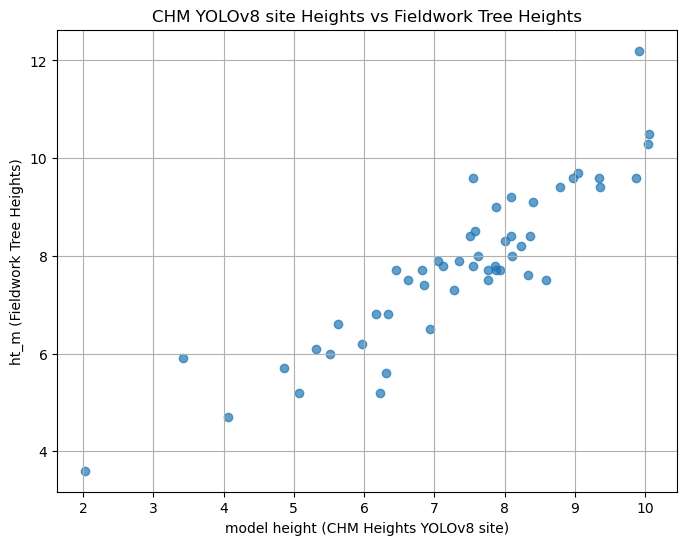

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(filtered_df['model_height_m'], filtered_df['ht_m'], alpha=0.7)
plt.xlabel('model height (CHM Heights YOLOv8 site)')
plt.ylabel('ht_m (Fieldwork Tree Heights)')
plt.title('CHM YOLOv8 site Heights vs Fieldwork Tree Heights')
plt.grid(True)
plt.show()

In [7]:
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Assuming your DataFrame is named 'df' with columns: 'tree_id', 'ht_m', 'model_height_m'

# 1. Calculate Metrics
r2 = r2_score(filtered_df['ht_m'], filtered_df['model_height_m'])
rmse = np.sqrt(mean_squared_error(filtered_df['ht_m'], filtered_df['model_height_m']))
bias = (filtered_df['model_height_m'] - filtered_df['ht_m']).mean()
mae = mean_absolute_error(filtered_df['ht_m'], filtered_df['model_height_m'])
pearson_r, _ = stats.pearsonr(filtered_df['ht_m'], filtered_df['model_height_m'])
spearman_r, _ = stats.spearmanr(filtered_df['ht_m'], filtered_df['model_height_m'])

# 2. Create a dictionary of results
metrics_dict = {
    "Metric": ["R²", "RMSE", "Bias", "MAE", "Pearson R", "Spearman R"],
    "Value": [r2, rmse, bias, mae, pearson_r, spearman_r]
}

# 3. Convert to DataFrame
metrics_df = pd.DataFrame(metrics_dict)

# 4. Save to CSV
metrics_df.to_csv("yolo_plots_height_model_metrics.csv", index=False)

print("Metrics saved to csv")

Metrics saved to csv


In [8]:
# merge merged_heights with crown_areas_trees.csv
# model_chm_pixel_count divided by 100 to get m^2


merged_areas = pd.merge(merged_heights_df, crown_areas, on='tree_id', how='inner')
merged_areas.head()

,tree_id,ht_m,model_height_m,model_chm_pixel_count,area_m2
0,p175t1,12.2,9.916355,10436,108.351518
1,p175t2,9.0,7.882053,5295,49.595770
2,p175t3,6.5,6.943157,2265,19.365237
3,p175t4,8.4,8.085491,2156,26.013008
4,p175t4,8.4,8.085491,2156,10.823893


In [9]:
merged_areas["model_area_m2"] = merged_areas["model_chm_pixel_count"]/100
merged_areas

,tree_id,ht_m,model_height_m,model_chm_pixel_count,area_m2,model_area_m2
0,p175t1,12.2,9.916355,10436,108.351518,104.36
1,p175t2,9.0,7.882053,5295,49.595770,52.95
2,p175t3,6.5,6.943157,2265,19.365237,22.65
3,p175t4,8.4,8.085491,2156,26.013008,21.56
4,p175t4,8.4,8.085491,2156,10.823893,21.56
5,p175t5,5.9,3.429642,585,9.273366,5.85
6,p175t6,7.7,6.458439,586,6.643948,5.86
7,p175t7,6.0,5.513695,1527,13.621602,15.27
8,p175t11,6.1,5.321918,2057,19.792938,20.57
9,p175t14,6.8,6.007679,2209,19.262165,22.09


In [10]:
def crown_area_metrics(
    df: pd.DataFrame,
    reference_col: str = "area_m2",
    model_col: str = "model_area_m2",
) -> pd.Series:
    """
    Calculate crown-area agreement metrics for matched reference/model crowns.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain reference and model crown-area columns.
    reference_col : str
        Reference crown area column name, in m².
    model_col : str
        Model-predicted crown area column name, in m².

    Returns
    -------
    pd.Series
        Summary metrics. Areas are reported in m²; relative metrics in percent.
    """
    required = {reference_col, model_col}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing required column(s): {sorted(missing)}")

    data = df[[reference_col, model_col]].copy()
    data[reference_col] = pd.to_numeric(data[reference_col], errors="coerce")
    data[model_col] = pd.to_numeric(data[model_col], errors="coerce")

    # Remove missing, infinite, and physically invalid crown areas.
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data = data[(data[reference_col] > 0) & (data[model_col] >= 0)]

    if len(data) < 2:
        raise ValueError(
            "At least two valid matched crowns are required. "
            "Reference areas must be > 0 and model areas must be >= 0."
        )

    reference = data[reference_col].to_numpy()
    model = data[model_col].to_numpy()

    error = model - reference
    absolute_error = np.abs(error)
    percent_error = 100 * error / reference

    rmse = np.sqrt(np.mean(error**2))
    pearson_r = np.corrcoef(reference, model)[0, 1]

    # Ordinary least-squares fit: model_area = intercept + slope * reference_area
    slope, intercept = np.polyfit(reference, model, deg=1)

    return pd.Series(
        {
            "n_matched_crowns": len(data),
            "mean_reference_area_m2": reference.mean(),
            "mean_model_area_m2": model.mean(),
            "MAE_m2": absolute_error.mean(),
            "median_AE_m2": np.median(absolute_error),
            "RMSE_m2": rmse,
            "rRMSE_percent": 100 * rmse / reference.mean(),
            "mean_bias_m2": error.mean(),
            "PBIAS_percent": 100 * error.sum() / reference.sum(),
            "median_absolute_percent_error": np.median(np.abs(percent_error)),
            "R2": r2_score(reference, model),
            "Pearson_r": pearson_r,
            "regression_slope": slope,
            "regression_intercept_m2": intercept,
        },
        name="crown_area_metrics",
    )

metrics = crown_area_metrics(merged_areas)
print(metrics.round(3))

# 4. Save to CSV
metrics.to_csv("20261007_yolo_site_area_model_metrics.csv", index=True)

n_matched_crowns                 55.000
mean_reference_area_m2           36.072
mean_model_area_m2               38.429
MAE_m2                            6.480
median_AE_m2                      3.423
RMSE_m2                          10.925
rRMSE_percent                    30.285
mean_bias_m2                      2.357
PBIAS_percent                     6.533
median_absolute_percent_error    11.799
R2                                0.791
Pearson_r                         0.904
regression_slope                  0.937
regression_intercept_m2           4.614
Name: crown_area_metrics, dtype: float64


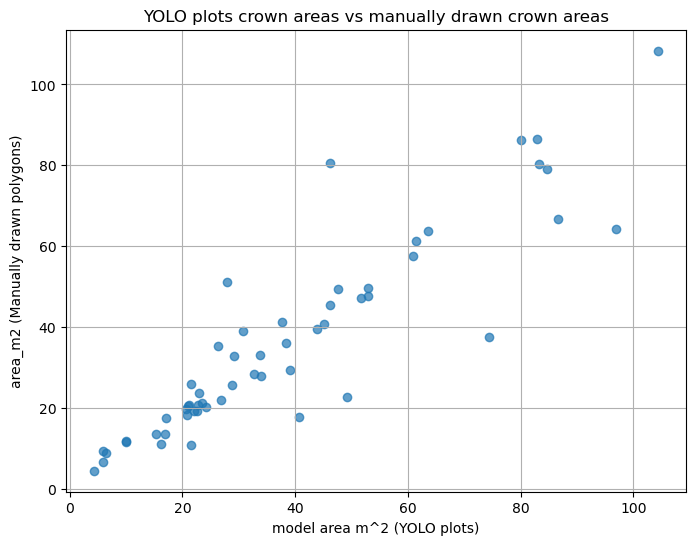

In [11]:

plt.figure(figsize=(8, 6))
plt.scatter(merged_areas['model_area_m2'], merged_areas['area_m2'], alpha=0.7)
plt.xlabel('model area m^2 (YOLO plots)')
plt.ylabel('area_m2 (Manually drawn polygons)')
plt.title('YOLO plots crown areas vs manually drawn crown areas')
plt.grid(True)
plt.show()